# Preprocessing Data Teknikal
## Log Return, Volatilitas Return (Y) & Fitur Teknikal (X1) - RSI, MA, Stochastic Oscillator

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45)
Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM

**Penulis**: Ilda Nurida (NRP 6032251068)
**Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Tujuan Notebook
1. Memuat `harga_saham_raw.csv` (7 emiten, Jan 2022 - Mei 2026) hasil notebook scraping
2. Menghitung **Log Return** harian per emiten
3. Menghitung **Volatilitas Return** (proksi standar deviasi log return, rolling window) sebagai **Variabel Dependen (Y)**
4. Mengekstraksi **fitur teknikal (X1)**:
   - RSI (Relative Strength Index)
   - Moving Average (MA) - SMA 5, 10, 20 hari
   - Stochastic Oscillator (%K, %D)
5. Menyimpan dataset hasil (`technical_features.csv`) sebagai input pipeline integrasi (X1 + Y)

### Definisi Variabel

| Variabel | Rumus | Keterangan |
|---|---|---|
| Log Return (`r_t`) | `r_t = ln(P_t / P_{t-1})` | `P_t` = harga penutupan hari ke-t |
| Volatilitas Return (`Y`) | `sigma_t = std(r_{t-w+1}, ..., r_t)` | Rolling standard deviation, window `w` hari |

### Catatan
- Data **time series** -> tidak dilakukan random shuffle, urutan kronologis per emiten dijaga
- Perhitungan dilakukan **per emiten** (group by `Kode_Emiten`) agar tidak tercampur antar saham
- Baris awal yang menghasilkan `NaN` (akibat rolling/lag) akan ditangani pada tahap akhir


## 1. Import Library & Konfigurasi

- Path input/output (relatif terhadap `02_preprocessing/teknikal/`)
- Parameter window untuk volatilitas, RSI, MA, dan Stochastic Oscillator

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
from pathlib import Path

# jangan hide semua warning saat debugging
warnings.filterwarnings("default")

# ── Direktori input/output (TETAP) ─────────────────────────
INPUT_DIR            = Path('../../03_dataset/raw')
OUTPUT_DIR           = Path('../../03_dataset/raw')
OUTPUT_DIR_DASHBOARD = Path('../../dashboard/data')

for d in (OUTPUT_DIR, OUTPUT_DIR_DASHBOARD):
    d.mkdir(parents=True, exist_ok=True)

FILE_INPUT  = 'harga_saham_raw.csv'
FILE_OUTPUT = 'technical_features.csv'

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

# ── Parameter perhitungan ─────────────────────────────────
VOLATILITY_WINDOW = 20
RSI_PERIOD        = 14
MA_WINDOWS        = [5, 10, 20]
STOCH_PERIOD      = 14
STOCH_SMOOTH_D    = 3

plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 10,
    'figure.dpi'     : 150,   # dari 110 → 150
    'axes.grid'      : True,
    'grid.alpha'     : 0.3,
})

# validasi file
input_path = INPUT_DIR / FILE_INPUT
if not input_path.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {input_path}")

print("=" * 70)
print("  KONFIGURASI PREPROCESSING TEKNIKAL")
print("=" * 70)
print(f"  Input file            : {input_path}")
print(f"  Output file           : {OUTPUT_DIR / FILE_OUTPUT}")
print(f"  Window volatilitas    : {VOLATILITY_WINDOW} hari")
print(f"  Periode RSI           : {RSI_PERIOD} hari")
print(f"  Window Moving Average : {MA_WINDOWS}")
print(f"  Periode Stochastic    : %K={STOCH_PERIOD}, %D={STOCH_SMOOTH_D}")
print("=" * 70)

print(f"pandas version : {pd.__version__}")
print(f"numpy version  : {np.__version__}")

  KONFIGURASI PREPROCESSING TEKNIKAL
  Input file            : ..\..\03_dataset\raw\harga_saham_raw.csv
  Output file           : ..\..\03_dataset\raw\technical_features.csv
  Window volatilitas    : 20 hari
  Periode RSI           : 14 hari
  Window Moving Average : [5, 10, 20]
  Periode Stochastic    : %K=14, %D=3
pandas version : 3.0.3
numpy version  : 2.4.6


## 2. Memuat Data Harga Saham

Memuat `harga_saham_raw.csv` hasil notebook scraping (7 emiten, OHLCV + Adj Close).
Data diurutkan berdasarkan `Kode_Emiten` lalu `Tanggal` untuk memastikan urutan
kronologis tetap terjaga pada setiap kelompok emiten.


In [3]:
csv_path = INPUT_DIR / FILE_INPUT

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

# Kandidat nama kolom tanggal
date_candidates = ['Tanggal', 'tanggal', 'Date', 'date', 'DATE']
date_col = next((c for c in date_candidates if c in df.columns), None)

if date_col is None:
    raise ValueError(f"Kolom tanggal tidak ditemukan. Kolom tersedia: {list(df.columns)}")

# Rename agar konsisten
if date_col != 'Tanggal':
    df = df.rename(columns={date_col: 'Tanggal'})

# Parse datetime
df['Tanggal'] = pd.to_datetime(df['Tanggal'], errors='coerce')

# Hapus timezone jika ada
if hasattr(df['Tanggal'].dt, 'tz') and df['Tanggal'].dt.tz is not None:
    df['Tanggal'] = df['Tanggal'].dt.tz_localize(None)

# Drop tanggal invalid
invalid_dates = df['Tanggal'].isna().sum()
if invalid_dates > 0:
    print(f"Warning: {invalid_dates} baris memiliki tanggal invalid dan akan dihapus")
    df = df.dropna(subset=['Tanggal']).copy()

# Validasi kolom penting
required_cols = ['Kode_Emiten', 'Open', 'High', 'Low', 'Close', 'Volume']
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_cols}")

# Cek duplicate
duplicates = df.duplicated(subset=['Kode_Emiten', 'Tanggal']).sum()
if duplicates > 0:
    print(f"Warning: ditemukan {duplicates} duplicate rows")
    df = df.drop_duplicates(subset=['Kode_Emiten', 'Tanggal'])

# Sort untuk time series
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# Rentang periode penelitian
START_DATE = df['Tanggal'].min().strftime('%Y-%m-%d')
END_DATE   = df['Tanggal'].max().strftime('%Y-%m-%d')

print("Import data telah berhasil")
print(f"Periode data : {START_DATE} s/d {END_DATE}")
print(f"Total baris  : {len(df):,}")
print(f"Jumlah emiten: {df['Kode_Emiten'].nunique()}")

Import data telah berhasil
Periode data : 2022-01-03 s/d 2026-06-17
Total baris  : 7,455
Jumlah emiten: 7


## 3. Perhitungan Log Return & Volatilitas Return
**Log Return**

Log return harian dihitung per emiten menggunakan harga **Adjusted Close**:


$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$




**Volatilitas Return**

Volatilitas return harian dihitung sebagai **rolling standard deviation**
dari log return dengan window `VOLATILITY_WINDOW` hari:


$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(R_i - \bar{R})^2}$$

>Rolling window = 20 hari trading (≈ 1 bulan)

In [4]:
# ============================================================
# CELL 3 — PERHITUNGAN LOG RETURN, VOLATILITAS, DAN TARGET
# ============================================================

print("=" * 90)
print("CELL 3 — PERHITUNGAN LOG RETURN, VOLATILITAS, DAN TARGET")
print("=" * 90)

# ============================================================
# 1. SORT DATA
# ============================================================
df = (
    df.sort_values(['Kode_Emiten', 'Tanggal'])
      .reset_index(drop=True)
)

kode_emiten_tersedia = sorted(df['Kode_Emiten'].dropna().unique())
print("Kode emiten:", ", ".join(kode_emiten_tersedia))

# ============================================================
# 2. LOG RETURN
# ============================================================
df['Log_Return'] = (
    df.groupby('Kode_Emiten')['Adj Close']
      .transform(lambda x: np.log(x / x.shift(1)))
)

df['Log_Return'] = df['Log_Return'].replace([np.inf, -np.inf], np.nan)

# ============================================================
# 3. VOLATILITAS RETURN (TARGET DASAR)
# ============================================================
df['Volatilitas_Return'] = (
    df.groupby('Kode_Emiten')['Log_Return']
      .transform(
          lambda x: x.rolling(
              window=VOLATILITY_WINDOW,
              min_periods=VOLATILITY_WINDOW
          ).std()
      )
)

group_vol = df.groupby('Kode_Emiten')['Volatilitas_Return']

# ============================================================
# 4. FEATURE ENGINEERING (ANTI LEAKAGE)
# ============================================================
df['Vol_Lag1'] = group_vol.shift(1)
df['Vol_Lag2'] = group_vol.shift(2)
df['Vol_Lag3'] = group_vol.shift(3)

df['Vol_MA5'] = (
    group_vol.transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

df['Vol_STD5'] = (
    group_vol.transform(
        lambda x: x.shift(1).rolling(5, min_periods=2).std()
    )
)

# ============================================================
# 5. TARGET FORECAST T+1
# ============================================================
df['Target_Volatility'] = (
    df.groupby('Kode_Emiten')['Volatilitas_Return']
      .shift(-1)
)

# ============================================================
# 6. PIVOT TABLE
# ============================================================
tabel_log_return = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='Log_Return'
    ).reindex(columns=URUTAN_EMITEN)
)

tabel_volatilitas = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='Volatilitas_Return'
    ).reindex(columns=URUTAN_EMITEN)
)

# ============================================================
# 7. SAVE CSV
# ============================================================
tabel_log_return.to_csv(
    OUTPUT_DIR / 'tabel_log_return.csv',
    encoding='utf-8-sig'
)

tabel_volatilitas.to_csv(
    OUTPUT_DIR / 'tabel_volatilitas_return.csv',
    encoding='utf-8-sig'
)

# ============================================================
# 8. SUMMARY
# ============================================================
print("\nJumlah NaN:")
kolom_cek = [
    'Log_Return',
    'Volatilitas_Return',
    'Vol_Lag1',
    'Vol_Lag2',
    'Vol_Lag3',
    'Target_Volatility'
]

for col in kolom_cek:
    print(f"{col:20s}: {df[col].isna().sum()}")

print("\nStatistik Volatilitas:")
print(df['Volatilitas_Return'].describe().round(6))

print("\nFeature baru berhasil dibuat:")
print("""
✓ Vol_Lag1
✓ Vol_Lag2
✓ Vol_Lag3
✓ Vol_MA5
✓ Vol_STD5
✓ Target_Volatility
""")

CELL 3 — PERHITUNGAN LOG RETURN, VOLATILITAS, DAN TARGET
Kode emiten: ADMR, ADRO, AKRA, ITMG, MEDC, PGAS, PTBA

Jumlah NaN:
Log_Return          : 7
Volatilitas_Return  : 140
Vol_Lag1            : 147
Vol_Lag2            : 154
Vol_Lag3            : 161
Target_Volatility   : 140

Statistik Volatilitas:
count    7315.000000
mean        0.024316
std         0.011257
min         0.004436
25%         0.016841
50%         0.022412
75%         0.029280
max         0.110206
Name: Volatilitas_Return, dtype: float64

Feature baru berhasil dibuat:

✓ Vol_Lag1
✓ Vol_Lag2
✓ Vol_Lag3
✓ Vol_MA5
✓ Vol_STD5
✓ Target_Volatility



## 3.1 Statistik Deskriptif Log Return & Volatilitas Return (Tabel 4.1 & 4.2)
**Statistik deskriptif Log Return**

Statistik deskriptif Log Return per emiten: jumlah observasi, rata-rata,
standar deviasi, nilai minimum-maksimum, kuartil, skewness, dan kurtosis.
Tabel ini menggambarkan karakteristik distribusi return harian masing-masing
emiten sektor energi.

**Statistik deskriptif Volatilitas Return**


Statistik deskriptif Volatilitas Return (Variabel Y) per emiten: jumlah
observasi, rata-rata, standar deviasi, nilai minimum-maksimum, kuartil, dan
rata-rata volatilitas tahunan (anualisasi dengan faktor akar 252 hari bursa).




> Rolling window = 20 hari trading (≈ 1 bulan)

In [5]:
# ============================================================
# CELL 4 — STATISTIK DESKRIPTIF LOG RETURN & VOLATILITAS
# ============================================================

grouped = df.groupby('Kode_Emiten')

# ============================================================
# TABEL 4.1 LOG RETURN
# ============================================================
rows_return = []

for kode in URUTAN_EMITEN:
    s = grouped.get_group(kode)['Log_Return'].dropna()

    rows_return.append({
        'Emiten'   : kode,
        'N (Hari)' : len(s),
        'Mean'     : round(s.mean(), 6),
        'Std Dev'  : round(s.std(), 6),
        'Min'      : round(s.min(), 6),
        'Q1 (25%)' : round(s.quantile(0.25), 6),
        'Median'   : round(s.median(), 6),
        'Q3 (75%)' : round(s.quantile(0.75), 6),
        'Max'      : round(s.max(), 6),
        'Skewness' : round(s.skew(), 4),
        'Kurtosis' : round(s.kurtosis(), 4),
    })

tabel_4_1 = pd.DataFrame(rows_return).set_index('Emiten')

path_tabel_4_1 = OUTPUT_DIR / 'tabel_4_1_deskriptif_log_return.csv'
tabel_4_1.to_csv(path_tabel_4_1, encoding='utf-8-sig')

print("=" * 80)
print("TABEL 4.1 - STATISTIK DESKRIPTIF LOG RETURN")
print("=" * 80)
display(tabel_4_1)

# ============================================================
# TABEL 4.2 VOLATILITAS
# ============================================================
rows_vol = []

for kode in URUTAN_EMITEN:
    s = grouped.get_group(kode)['Volatilitas_Return'].dropna()

    mean_vol = s.mean()

    rows_vol.append({
        'Emiten'            : kode,
        'N (Hari)'          : len(s),
        'Mean'              : round(mean_vol, 6),
        'Std Dev'           : round(s.std(), 6),
        'Min'               : round(s.min(), 6),
        'Q1 (25%)'          : round(s.quantile(0.25), 6),
        'Median'            : round(s.median(), 6),
        'Q3 (75%)'          : round(s.quantile(0.75), 6),
        'Max'               : round(s.max(), 6),
        'Vol Annual (Mean)' : round(mean_vol * np.sqrt(252), 4),
    })

tabel_4_2 = pd.DataFrame(rows_vol).set_index('Emiten')

path_tabel_4_2 = OUTPUT_DIR / 'tabel_4_2_deskriptif_volatilitas.csv'
tabel_4_2.to_csv(path_tabel_4_2, encoding='utf-8-sig')

print("=" * 80)
print("TABEL 4.2 - STATISTIK DESKRIPTIF VOLATILITAS RETURN")
print("=" * 80)
display(tabel_4_2)

print(f"\nDisimpan: {path_tabel_4_1}")
print(f"Disimpan: {path_tabel_4_2}")

TABEL 4.1 - STATISTIK DESKRIPTIF LOG RETURN


,N (Hari),Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Skewness,Kurtosis
Emiten,,,,,,,,,,
ADRO,1064,0.001003,0.027364,-0.282863,-0.012729,0.0,0.013423,0.177195,-0.2756,14.6892
ADMR,1064,0.002394,0.041520,-0.130362,-0.020290,0.0,0.019513,0.298732,1.8263,9.1384
ITMG,1064,0.000846,0.019932,-0.072238,-0.008523,0.0,0.009646,0.117899,0.3674,3.8367
PTBA,1064,0.000702,0.020983,-0.161586,-0.009061,0.0,0.008975,0.189605,0.5550,11.2446
MEDC,1064,0.001069,0.031824,-0.160623,-0.016826,0.0,0.017857,0.186984,0.4553,3.2804
AKRA,1064,0.000618,0.025387,-0.121214,-0.011988,0.0,0.013389,0.200671,0.4648,5.1128
PGAS,1064,0.000529,0.020324,-0.145050,-0.009860,0.0,0.010782,0.107631,-0.1460,4.4825


TABEL 4.2 - STATISTIK DESKRIPTIF VOLATILITAS RETURN


,N (Hari),Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Vol Annual (Mean)
Emiten,,,,,,,,,
ADRO,1045,0.025138,0.011415,0.009189,0.018842,0.022854,0.028373,0.090462,0.3991
ADMR,1045,0.034345,0.013010,0.009526,0.024642,0.032015,0.041132,0.110206,0.5452
ITMG,1045,0.018119,0.008254,0.004436,0.011047,0.016769,0.023914,0.039396,0.2876
PTBA,1045,0.019101,0.008817,0.005605,0.013398,0.017629,0.022548,0.062072,0.3032
MEDC,1045,0.030354,0.009876,0.011549,0.023919,0.028686,0.034927,0.062738,0.4819
AKRA,1045,0.024030,0.008634,0.009007,0.018701,0.023043,0.028366,0.065695,0.3815
PGAS,1045,0.019125,0.006301,0.007216,0.014697,0.018486,0.022351,0.042946,0.3036



Disimpan: ..\..\03_dataset\raw\tabel_4_1_deskriptif_log_return.csv
Disimpan: ..\..\03_dataset\raw\tabel_4_2_deskriptif_volatilitas.csv


## 3.2 Grafik Time Series Log Return (Gambar 4.1)

Grafik pergerakan Log Return harian untuk masing-masing emiten selama periode penelitian. Fluktuasi return yang besar mengindikasikan periode volatilitas tinggi pada saham tersebut.

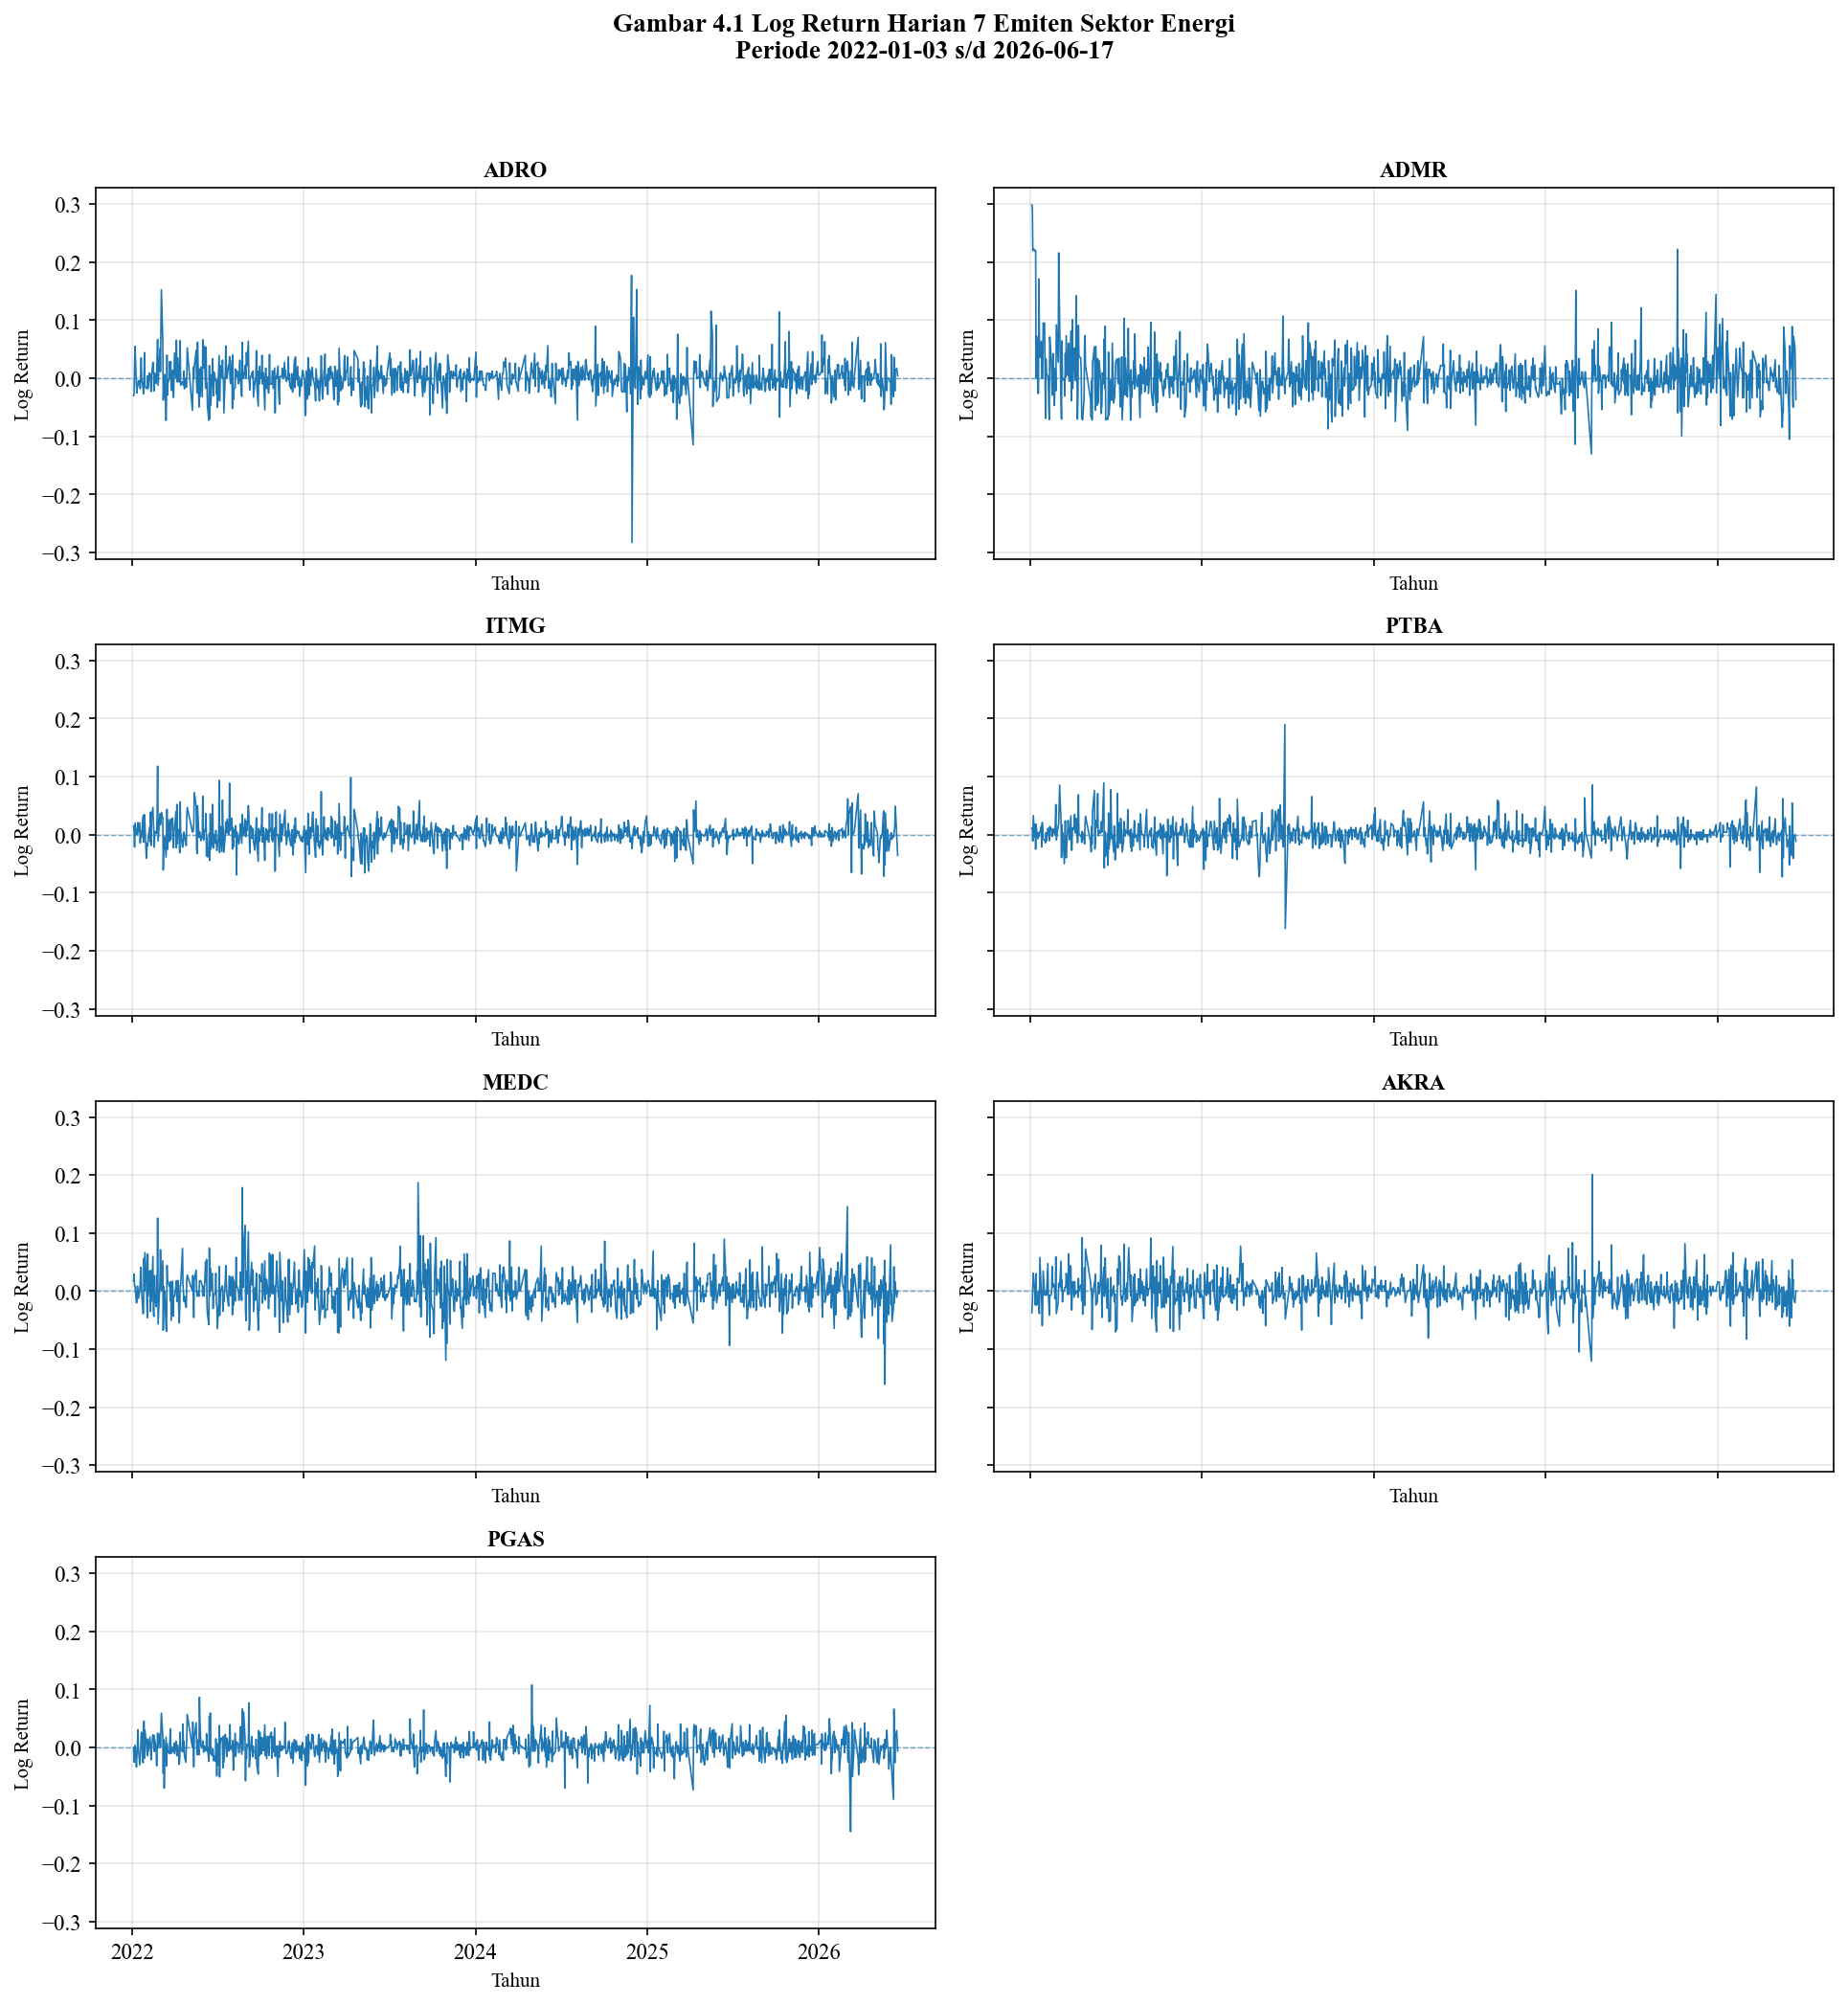

Gambar tersimpan: ..\..\dashboard\data\gambar_4_1_log_return.png


In [13]:
# ============================================================
# CELL 5 — VISUALISASI LOG RETURN HARIAN
# ============================================================

fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 14),
    sharex=True,
    sharey=True
)

axes = axes.flatten()
grouped = df.groupby('Kode_Emiten')

for i, kode in enumerate(URUTAN_EMITEN):
    sub = grouped.get_group(kode)
    ax = axes[i]

    ax.plot(
        sub['Tanggal'],
        sub['Log_Return'],
        linewidth=0.8
    )

    ax.axhline(
        y=0,
        linestyle='--',
        linewidth=0.7,
        alpha=0.6
    )

    ax.set_title(kode, fontweight='bold')
    ax.set_xlabel('Tahun')
    ax.set_ylabel('Log Return')

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# subplot ke-8 kosong
axes[-1].axis('off')

fig.suptitle(
    'Gambar 4.1 Log Return Harian 7 Emiten Sektor Energi\n'
    f'Periode {START_DATE} s/d {END_DATE}',
    fontsize=13,
    fontweight='bold',
    y=0.995
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar_4_1 = OUTPUT_DIR_DASHBOARD / 'gambar_4_1_log_return.png'

fig.savefig(
    path_gambar_4_1,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(f"Gambar tersimpan: {path_gambar_4_1}")

## 4. Fitur Teknikal: RSI (Relative Strength Index)

RSI mengukur kekuatan momentum harga dalam rentang 0-100:

$$ RSI_t = 100 - \frac{100}{1 + RS_t}, \qquad RS_t = \frac{\text{rata-rata gain}_{14}}{\text{rata-rata loss}_{14}} $$

Dihitung menggunakan metode **Wilder's smoothing** (exponential moving average
dengan `alpha = 1/periode`), sesuai standar perhitungan RSI 14 hari.


In [12]:
# ============================================================
# CELL — RELATIVE STRENGTH INDEX (RSI)
# ============================================================

def hitung_rsi(group, period=RSI_PERIOD):
    """Menghitung RSI per emiten menggunakan Adj Close"""

    delta = group['Adj Close'].diff()

    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.rolling(
        window=period,
        min_periods=period
    ).mean()

    avg_loss = loss.rolling(
        window=period,
        min_periods=period
    ).mean()

    avg_loss = avg_loss.replace(0, np.nan)

    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))

    return rsi.clip(lower=0, upper=100)


df['RSI'] = (
    df.groupby('Kode_Emiten', group_keys=False)
      .apply(lambda g: hitung_rsi(g))
      .reset_index(level=0, drop=True)
)

print(f"RSI ({RSI_PERIOD} hari) berhasil dihitung")

# ============================================================
# TABEL RSI
# ============================================================
tabel_rsi = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='RSI'
    )
    .reindex(columns=URUTAN_EMITEN)
    .dropna(how='all')
)

tabel_fmt = tabel_rsi.round(2).astype(object)

tabel_display = pd.concat([
    tabel_fmt.head(5),
    pd.DataFrame(
        [['...'] * len(tabel_fmt.columns)],
        columns=tabel_fmt.columns,
        index=['...']
    ),
    tabel_fmt.tail(5)
])

tabel_display.index = tabel_display.index.map(
    lambda x: x.strftime('%Y-%m-%d')
    if hasattr(x, 'strftime') else x
)

tabel_display.index.name = 'Tanggal'

print("=" * 80)
print("TABEL RSI - 7 EMITEN")
print("=" * 80)
display(tabel_display)

RSI (14 hari) berhasil dihitung
TABEL RSI - 7 EMITEN


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-21,45.16,95.7,70.09,68.18,77.36,37.32,39.66
2022-01-24,47.46,95.78,73.68,68.89,62.71,41.25,35.38
2022-01-25,47.46,95.49,66.91,58.33,49.18,40.61,38.33
2022-01-26,41.51,95.16,77.52,66.67,57.53,32.89,50.72
2022-01-27,38.0,94.67,79.72,62.22,56.34,24.66,46.58
...,...,...,...,...,...,...,...
2026-06-10,55.38,55.93,31.74,45.56,24.46,33.7,39.53
2026-06-11,52.94,56.25,50.38,45.56,39.18,41.38,34.8
2026-06-12,43.86,55.49,54.17,44.44,37.89,38.64,38.03


## 5. Fitur Teknikal: Moving Average (MA)

Simple Moving Average (SMA) dihitung untuk beberapa periode (5, 10, 20 hari)
sebagai indikator tren harga jangka pendek-menengah:

$$ MA_t^{(n)} = \frac{1}{n}\sum_{i=0}^{n-1} P_{t-i} $$


In [10]:
# ============================================================
# CELL — MOVING AVERAGE FEATURES
# ============================================================

for window in MA_WINDOWS:
    ma_col = f'MA_{window}'
    dist_col = f'Dist_MA_{window}'

    # Moving Average per emiten
    df[ma_col] = (
        df.groupby('Kode_Emiten')['Adj Close']
          .transform(
              lambda x: x.rolling(
                  window=window,
                  min_periods=window
              ).mean()
          )
    )

    # Distance terhadap MA (feature tambahan untuk modeling)
    df[dist_col] = (
        (df['Adj Close'] - df[ma_col]) / df[ma_col]
    )

ma_cols = [f'MA_{w}' for w in MA_WINDOWS]

# ============================================================
# TABEL PER MA
# ============================================================
tabel_ma = {}

for ma in ma_cols:
    tabel = (
        df.pivot(
            index='Tanggal',
            columns='Kode_Emiten',
            values=ma
        )
        .reindex(columns=URUTAN_EMITEN)
    )

    tabel_ma[ma] = tabel.dropna(how='all')

    print("=" * 80)
    print(f"TABEL {ma} - 7 EMITEN")
    print("=" * 80)

    display(
        pd.concat([
            tabel_ma[ma].head(5),
            tabel_ma[ma].tail(5)
        ]).round(2)
    )
    print()

print("Feature baru:")
for window in MA_WINDOWS:
    print(f"✓ MA_{window}")
    print(f"✓ Dist_MA_{window}")

TABEL MA_5 - 7 EMITEN


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-07,786.92,230.97,9275.28,1194.04,392.52,615.07,874.48
2022-01-10,788.95,293.86,9315.00,1203.70,395.80,613.32,863.02
2022-01-11,791.65,369.55,9338.37,1215.13,396.46,613.32,849.66
2022-01-12,796.38,460.64,9350.05,1217.76,395.47,612.74,841.38
2022-01-13,795.03,540.60,9441.17,1227.43,393.84,614.63,840.11
2026-06-10,2246.00,1471.00,21930.00,2509.00,1180.09,1217.00,1505.88
2026-06-11,2242.00,1488.00,21985.00,2503.26,1169.38,1224.00,1487.00
2026-06-12,2250.00,1523.00,22300.00,2509.00,1173.27,1230.00,1489.00
2026-06-15,2280.00,1565.00,22600.00,2531.93,1181.44,1242.00,1526.00



TABEL MA_10 - 7 EMITEN


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-14,785.57,423.82,9389.77,1212.49,391.54,612.45,856.34
2022-01-17,781.85,482.72,9459.86,1218.64,392.36,607.94,849.98
2022-01-18,779.14,535.41,9501.91,1223.91,393.18,605.75,842.34
2022-01-19,778.81,595.33,9543.96,1227.43,394.49,602.92,836.61
2022-01-20,779.14,655.25,9600.04,1232.70,397.11,597.31,833.75
2026-06-10,2259.00,1466.00,22127.50,2576.83,1202.97,1238.50,1607.61
2026-06-11,2254.00,1461.50,22090.00,2556.77,1199.08,1236.00,1581.95
2026-06-12,2252.00,1468.00,22165.00,2535.75,1196.16,1232.00,1559.29
2026-06-15,2254.00,1481.00,22292.50,2520.46,1196.83,1231.00,1547.61



TABEL MA_20 - 7 EMITEN


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-28,774.92,661.79,9679.47,1230.50,402.15,586.58,846.79
2022-01-31,772.72,714.43,9726.78,1234.46,405.96,581.41,846.16
2022-02-02,771.20,760.95,9759.49,1236.87,408.42,577.23,844.88
2022-02-03,770.86,806.45,9779.94,1238.85,411.73,573.63,845.36
2022-02-04,768.83,849.63,9807.39,1240.83,414.68,569.55,846.00
2026-06-10,2316.50,1525.50,22778.75,2620.31,1308.61,1315.00,1658.94
2026-06-11,2303.00,1510.00,22698.75,2610.75,1291.33,1305.50,1648.19
2026-06-12,2291.00,1500.00,22675.00,2600.72,1274.54,1295.25,1638.95
2026-06-15,2281.00,1494.25,22646.25,2590.69,1257.10,1283.75,1631.95



Feature baru:
✓ MA_5
✓ Dist_MA_5
✓ MA_10
✓ Dist_MA_10
✓ MA_20
✓ Dist_MA_20


## 6. Fitur Teknikal: Stochastic Oscillator

Stochastic Oscillator mengukur posisi harga penutupan relatif terhadap
rentang harga tertinggi-terendah dalam periode tertentu:

$$ \%K_t = 100 \times \frac{C_t - L_{n}}{H_{n} - L_{n}} $$

$$ \%D_t = SMA(\%K_t, m) $$

dengan `H_n` dan `L_n` adalah harga tertinggi (`High`) dan terendah (`Low`)
selama `n` hari terakhir (`STOCH_PERIOD`), dan `%D` adalah SMA dari `%K`
selama `m` hari (`STOCH_SMOOTH_D`).


In [11]:
# ============================================================
# CELL — STOCHASTIC OSCILLATOR
# ============================================================

def hitung_stochastic(group, n=STOCH_PERIOD, m=STOCH_SMOOTH_D):
    """Hitung %K dan %D Stochastic Oscillator per emiten"""

    lowest_low = group['Low'].rolling(
        window=n,
        min_periods=n
    ).min()

    highest_high = group['High'].rolling(
        window=n,
        min_periods=n
    ).max()

    denominator = (highest_high - lowest_low)

    # Hindari division by zero
    denominator = denominator.replace(0, np.nan)

    percent_k = (
        100 * (group['Adj Close'] - lowest_low) / denominator
    )

    percent_k = percent_k.clip(lower=0, upper=100)

    percent_d = percent_k.rolling(
        window=m,
        min_periods=m
    ).mean()

    return pd.DataFrame({
        'Stoch_%K': percent_k,
        'Stoch_%D': percent_d
    }, index=group.index)


stoch_result = (
    df.groupby('Kode_Emiten', group_keys=False)
      .apply(lambda g: hitung_stochastic(g))
)

df['Stoch_%K'] = stoch_result['Stoch_%K']
df['Stoch_%D'] = stoch_result['Stoch_%D']

# Feature tambahan untuk modeling
df['Stoch_Signal'] = df['Stoch_%K'] - df['Stoch_%D']

print(
    f"Stochastic Oscillator berhasil dihitung "
    f"(%K={STOCH_PERIOD}, %D={STOCH_SMOOTH_D})"
)

# ============================================================
# DISPLAY TABLE
# ============================================================
for metric, nama in [('Stoch_%K', '%K'), ('Stoch_%D', '%D')]:

    tabel = (
        df.pivot(
            index='Tanggal',
            columns='Kode_Emiten',
            values=metric
        )
        .reindex(columns=URUTAN_EMITEN)
        .dropna(how='all')
    )

    tabel_fmt = tabel.round(2).astype(object)

    tabel_display = pd.concat([
        tabel_fmt.head(5),
        pd.DataFrame(
            [['...'] * len(tabel_fmt.columns)],
            columns=tabel_fmt.columns,
            index=['...']
        ),
        tabel_fmt.tail(5)
    ])

    tabel_display.index = tabel_display.index.map(
        lambda x: x.strftime('%Y-%m-%d')
        if hasattr(x, 'strftime') else x
    )

    tabel_display.index.name = 'Tanggal'

    print("=" * 80)
    print(f"TABEL STOCHASTIC OSCILLATOR {nama} - 7 EMITEN")
    print("=" * 80)
    display(tabel_display)
    print()

print("Feature tambahan:")
print("✓ Stoch_Signal")

Stochastic Oscillator berhasil dihitung (%K=14, %D=3)
TABEL STOCHASTIC OSCILLATOR %K - 7 EMITEN


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-20,0.0,84.8,0.0,0.0,0.0,0.0,0.0
2022-01-21,0.0,87.84,0.0,0.0,0.0,0.0,0.0
2022-01-24,0.0,88.7,0.0,0.0,0.0,0.0,0.0
2022-01-25,0.0,87.46,0.0,0.0,0.0,0.0,0.0
2022-01-26,0.0,86.08,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...
2026-06-10,76.0,67.9,29.89,38.52,10.13,37.74,33.33
2026-06-11,56.0,49.38,53.33,12.88,26.25,55.56,26.32
2026-06-12,68.0,76.54,87.63,10.55,30.96,48.89,31.58



TABEL STOCHASTIC OSCILLATOR %D - 7 EMITEN


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-24,0.0,87.11,0.0,0.0,0.0,0.0,0.0
2022-01-25,0.0,88.0,0.0,0.0,0.0,0.0,0.0
2022-01-26,0.0,87.42,0.0,0.0,0.0,0.0,0.0
2022-01-27,0.0,85.81,0.0,0.0,0.0,0.0,0.0
2022-01-28,0.0,85.77,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...
2026-06-10,49.56,63.15,21.26,17.91,9.71,25.46,19.62
2026-06-11,62.67,65.43,34.64,22.2,17.15,42.42,27.78
2026-06-12,66.67,64.61,56.95,20.65,22.45,47.39,30.41



Feature tambahan:
✓ Stoch_Signal


## 7. Ringkasan Dataset Hasil Preprocessing

Menampilkan struktur akhir dataset (`technical_features.csv`) berisi seluruh
fitur teknikal X1 dan variabel Y, beserta pemeriksaan jumlah `NaN` per kolom.


In [15]:
# ============================================================
# CELL — RINGKASAN DATASET FINAL PREPROCESSING TEKNIKAL
# ============================================================

kolom_fitur = [
    'Tanggal',
    'Kode_Emiten',
    'Nama_Perusahaan',
    'Open',
    'High',
    'Low',
    'Close',
    'Adj Close',
    'Volume',
    'Log_Return',
    'Volatilitas_Return',
    'Vol_Lag1',
    'Vol_Lag2',
    'Vol_Lag3',
    'Vol_MA5',
    'Vol_STD5',
    'RSI'
] + ma_cols + [
    'Stoch_%K',
    'Stoch_%D'
]

missing_cols = [c for c in kolom_fitur if c not in df.columns]

if missing_cols:
    raise KeyError(f"Kolom berikut tidak ditemukan: {missing_cols}")

df_final = df[kolom_fitur].copy()

print("=" * 75)
print("RINGKASAN DATASET HASIL PREPROCESSING TEKNIKAL")
print("=" * 75)

print(f"Total baris   : {len(df_final):,}")
print(f"Total kolom   : {len(df_final.columns)}")
print(f"Jumlah emiten : {df_final['Kode_Emiten'].nunique()}")

print(
    f"Periode       : "
    f"{df_final['Tanggal'].min().date()} s/d "
    f"{df_final['Tanggal'].max().date()}"
)

print("-" * 75)
print("Jumlah observasi per emiten:")

for kode, n in df_final.groupby('Kode_Emiten').size().items():
    print(f"  {kode:6s}: {n:,} baris")

print("-" * 75)
print("Jumlah NaN per kolom:")

nan_summary = df_final.isna().sum()
nan_summary = nan_summary[nan_summary > 0]

for col, n_nan in nan_summary.items():
    pct = (n_nan / len(df_final)) * 100
    print(f"  {col:22s}: {n_nan:5d} baris ({pct:.2f}%)")

print("=" * 75)

RINGKASAN DATASET HASIL PREPROCESSING TEKNIKAL
Total baris   : 7,455
Total kolom   : 22
Jumlah emiten : 7
Periode       : 2022-01-03 s/d 2026-06-17
---------------------------------------------------------------------------
Jumlah observasi per emiten:
  ADMR  : 1,065 baris
  ADRO  : 1,065 baris
  AKRA  : 1,065 baris
  ITMG  : 1,065 baris
  MEDC  : 1,065 baris
  PGAS  : 1,065 baris
  PTBA  : 1,065 baris
---------------------------------------------------------------------------
Jumlah NaN per kolom:
  Log_Return            :     7 baris (0.09%)
  Volatilitas_Return    :   140 baris (1.88%)
  Vol_Lag1              :   147 baris (1.97%)
  Vol_Lag2              :   154 baris (2.07%)
  Vol_Lag3              :   161 baris (2.16%)
  Vol_MA5               :   147 baris (1.97%)
  Vol_STD5              :   154 baris (2.07%)
  RSI                   :    98 baris (1.31%)
  MA_5                  :    28 baris (0.38%)
  MA_10                 :    63 baris (0.85%)
  MA_20                 :   133 bar

## 8. Visualisasi Volatilitas Return Saham (Gambar 4.2)

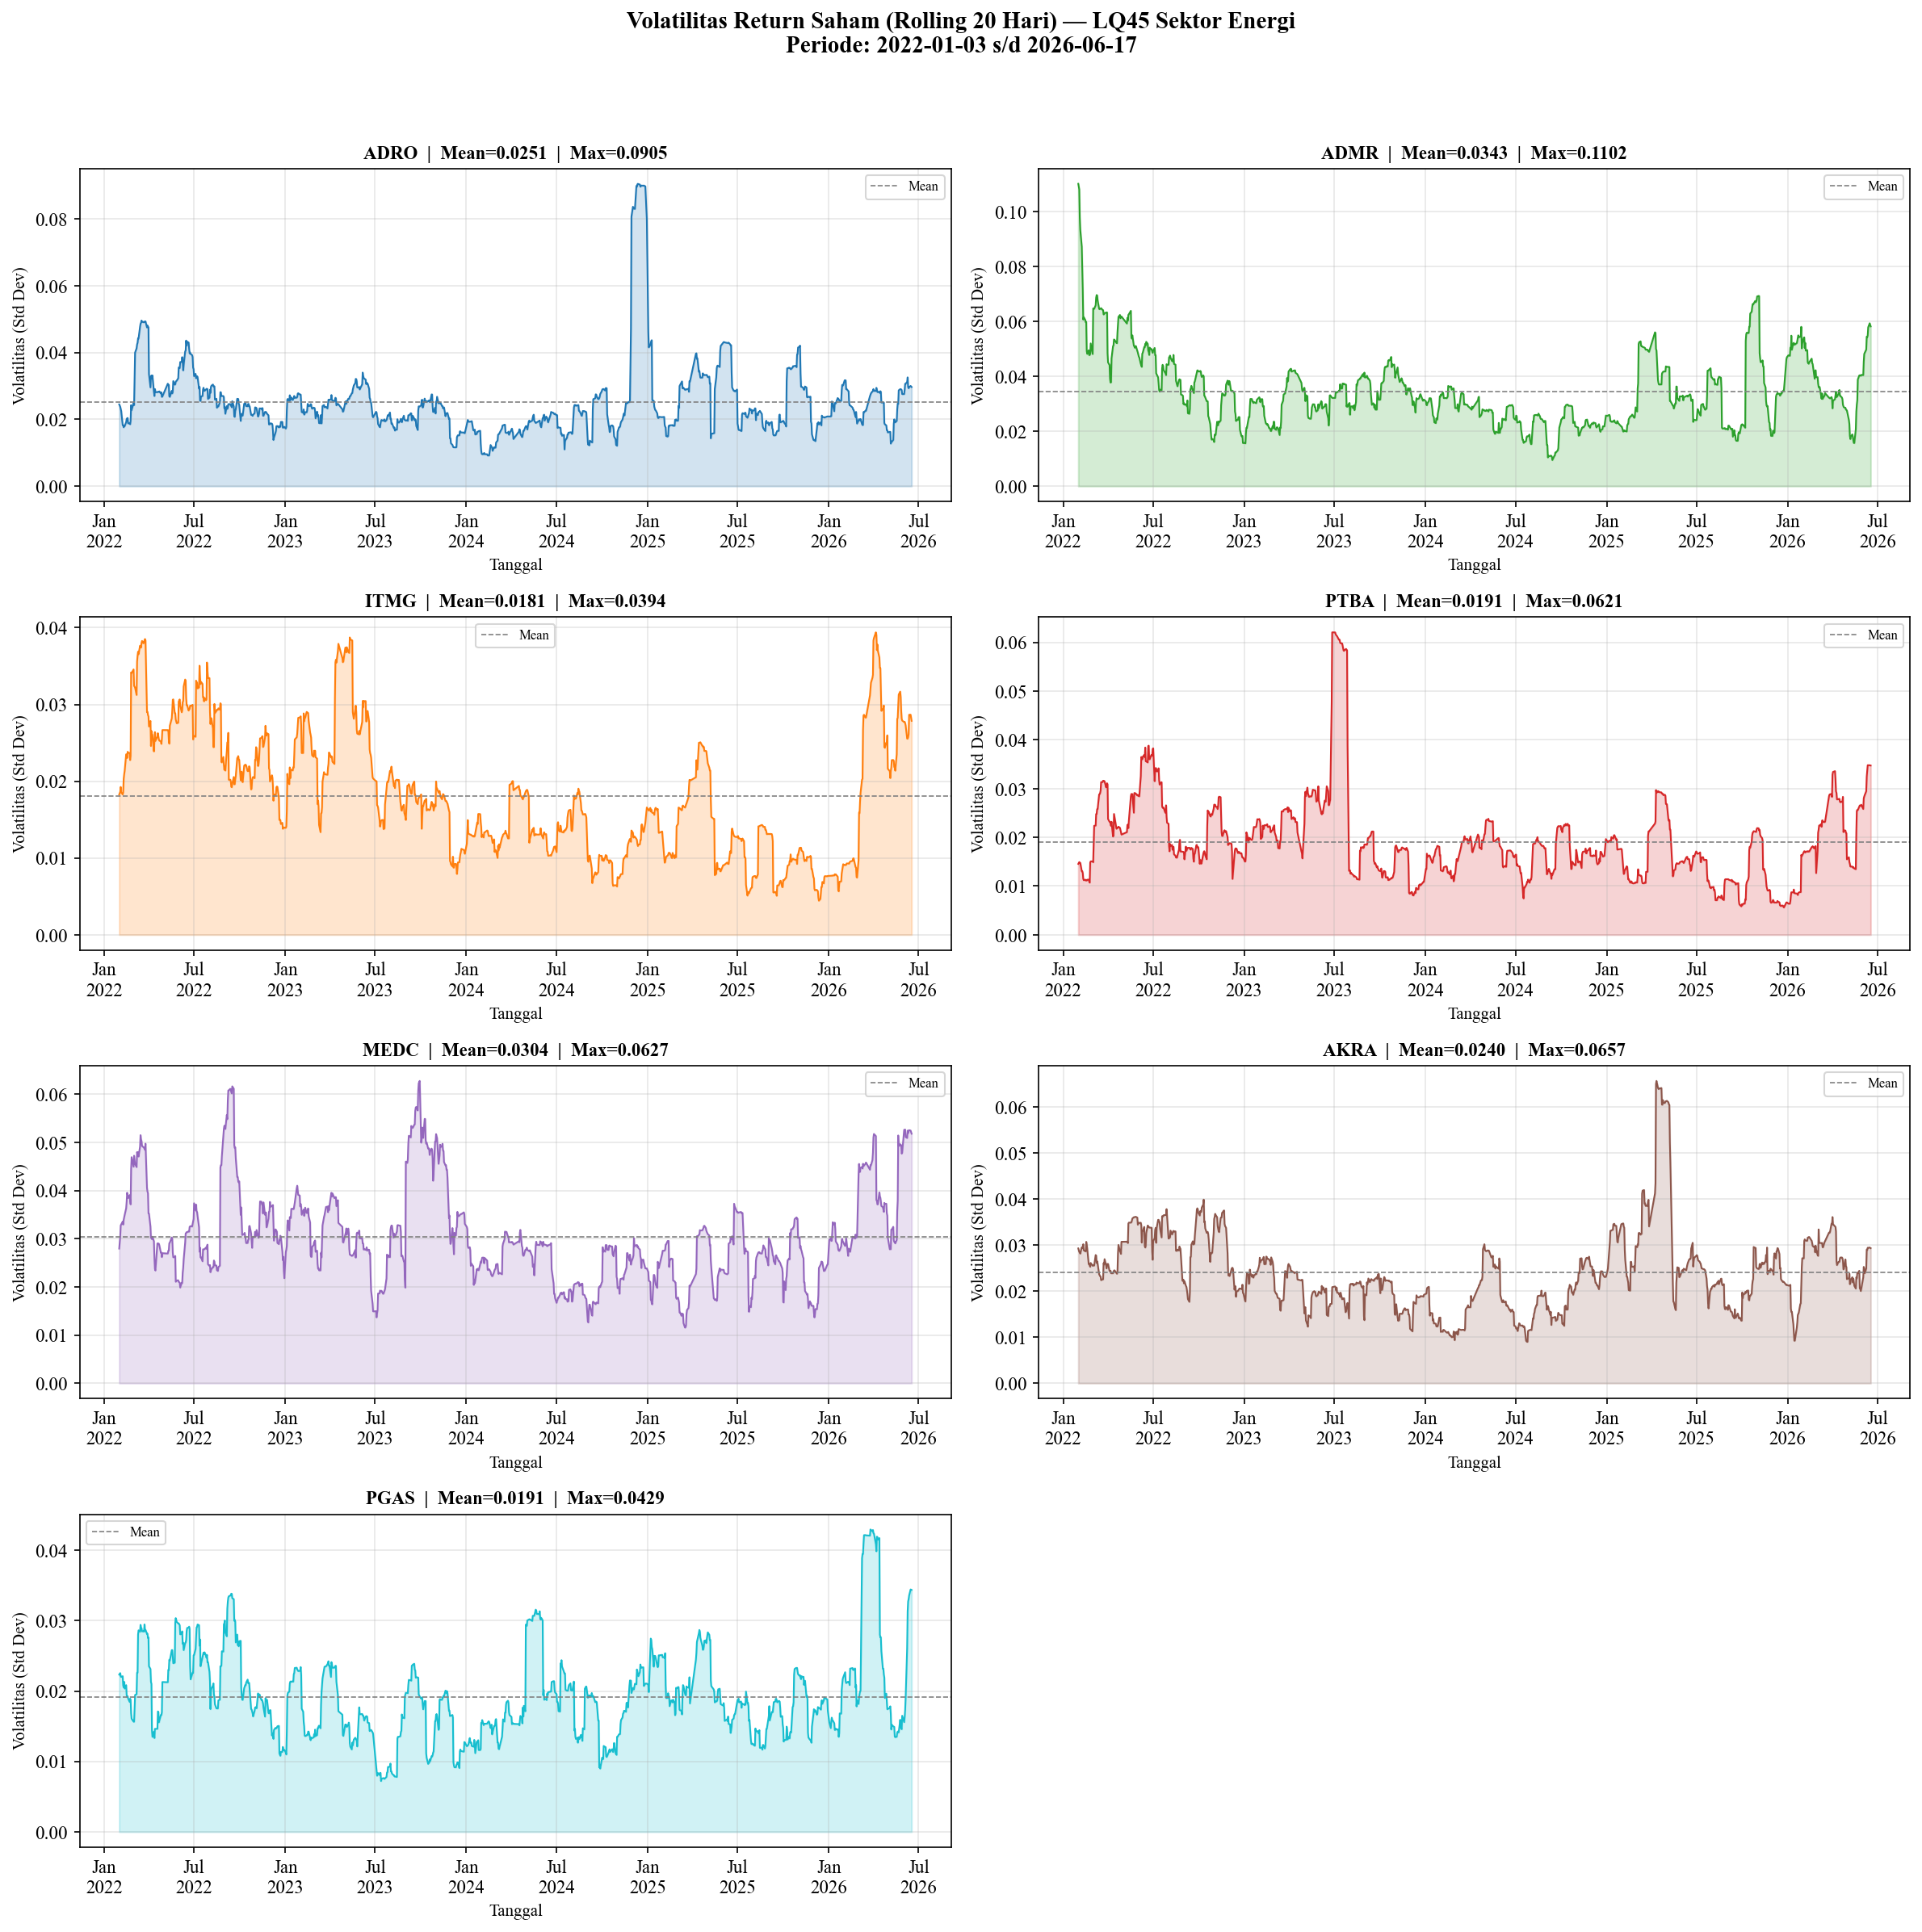

Gambar disimpan: ..\..\dashboard\data\gambar_volatilitas_return_per6bulan.png


In [22]:
WARNA = {
    'ADRO': '#1f77b4', 'ADMR': '#2ca02c', 'ITMG': '#ff7f0e',
    'PTBA': '#d62728', 'MEDC': '#9467bd', 'AKRA': '#8c564b', 'PGAS': '#17becf',
}

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes = axes.flatten()

fig.suptitle(
    f'Volatilitas Return Saham (Rolling {VOLATILITY_WINDOW} Hari) — LQ45 Sektor Energi\n'
    f'Periode: {START_DATE} s/d {END_DATE}',
    fontsize=14, fontweight='bold', y=0.995
)

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_e = df[df['Kode_Emiten'] == kode].dropna(subset=['Volatilitas_Return'])

    ax.plot(
        df_e['Tanggal'], df_e['Volatilitas_Return'],
        color=WARNA[kode], linewidth=1.0
    )
    ax.fill_between(
        df_e['Tanggal'], df_e['Volatilitas_Return'],
        alpha=0.2, color=WARNA[kode]
    )

    vol_mean = df_e['Volatilitas_Return'].mean()
    vol_max  = df_e['Volatilitas_Return'].max()
    ax.axhline(vol_mean, color='gray', linestyle='--', linewidth=0.8, label='Mean')

    ax.set_title(f'{kode}  |  Mean={vol_mean:.4f}  |  Max={vol_max:.4f}',
                  fontsize=11, fontweight='bold')
    ax.set_xlabel('Tanggal')
    ax.set_ylabel('Volatilitas (Std Dev)')

    # Sumbu x per 6 bulan (Jun/Dec)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].axis('off')   # panel ke-8 kosong (7 emiten pada grid 4x2)

plt.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar = OUTPUT_DIR_DASHBOARD / 'gambar_volatilitas_return_per6bulan.png'
plt.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_gambar}")

## 9. Heatmap Korelasi Volatilitas Antar Emiten (Gambar 4.3)

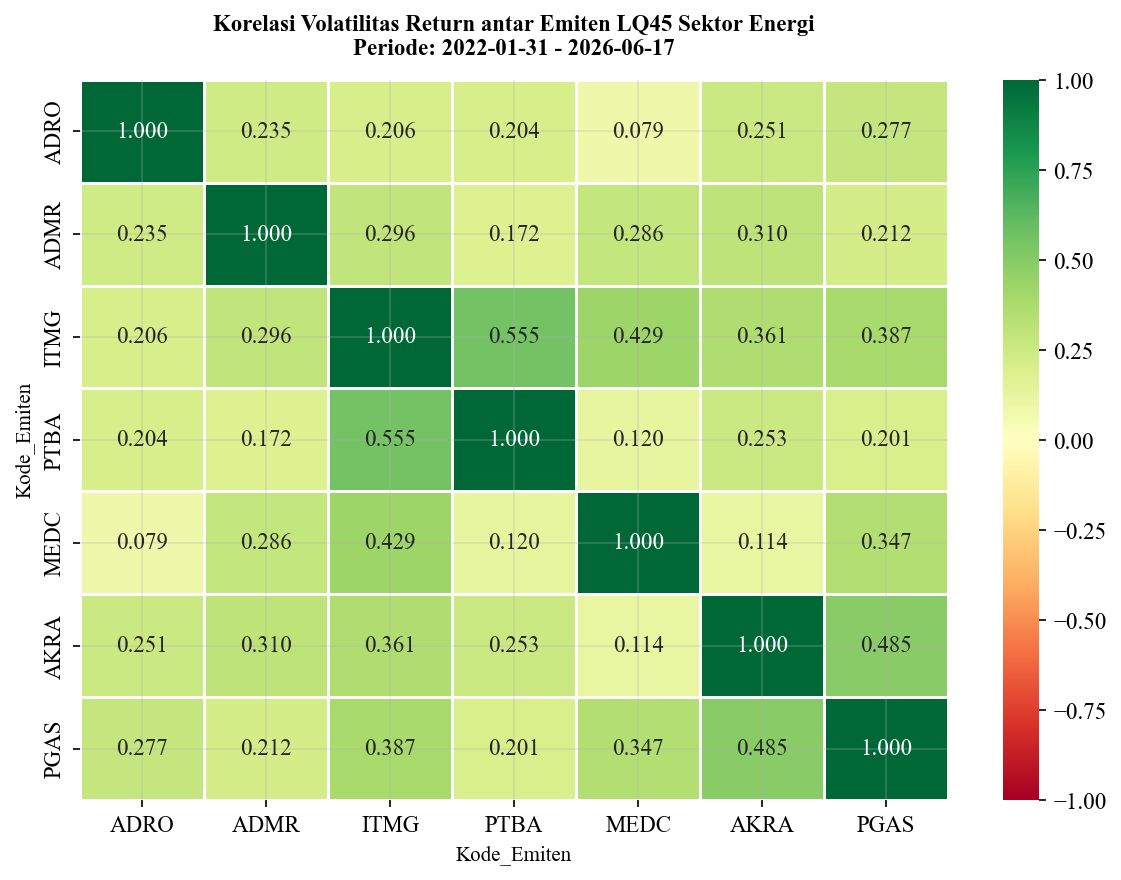

Gambar disimpan: ..\..\dashboard\data\gambar_heatmap_korelasi_volatilitas.png


In [23]:
import seaborn as sns

# Pivot volatilitas return: baris=Tanggal, kolom=7 Emiten
df_pivot_vol = (
    df.pivot_table(index='Tanggal', columns='Kode_Emiten', values='Volatilitas_Return')
      .reindex(columns=URUTAN_EMITEN)
      .dropna()
)

corr_vol = df_pivot_vol.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_vol, annot=True, fmt='.3f', cmap='RdYlGn',
    center=0, linewidths=0.5, vmin=-1, vmax=1, ax=ax
)
ax.set_title(
    f'Korelasi Volatilitas Return antar Emiten LQ45 Sektor Energi\n'
    f'Periode: {df_pivot_vol.index.min().date()} - {df_pivot_vol.index.max().date()}',
    fontweight='bold', pad=12
)
plt.tight_layout()

path_heatmap = OUTPUT_DIR_DASHBOARD / 'gambar_heatmap_korelasi_volatilitas.png'
plt.savefig(path_heatmap, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_heatmap}")

## 10. Penanganan Baris dengan Nilai NaN

Baris-baris awal pada setiap emiten yang mengandung `NaN` (akibat perhitungan
rolling/lag) **dihapus**, karena belum memiliki nilai fitur teknikal maupun
volatilitas yang valid. Jumlah baris yang hilang per emiten setara dengan
periode rolling terbesar (Stochastic Oscillator, `STOCH_PERIOD` hari).


In [26]:
# ============================================================
# CELL FINAL CLEANING — HAPUS NaN AKIBAT ROLLING WINDOW
# ============================================================

jumlah_sebelum = len(df_final)

# Hapus seluruh baris yang masih mengandung NaN
df_final_clean = df_final.dropna().reset_index(drop=True)

jumlah_sesudah = len(df_final_clean)
jumlah_dihapus = jumlah_sebelum - jumlah_sesudah
persen_dihapus = (jumlah_dihapus / jumlah_sebelum) * 100

# Validasi final
remaining_nan = df_final_clean.isna().sum().sum()
if remaining_nan > 0:
    raise ValueError(f"Masih ada {remaining_nan} NaN setelah cleaning")

print("=" * 75)
print("RINGKASAN CLEANING DATA FINAL")
print("=" * 75)
print(f"Jumlah baris sebelum : {jumlah_sebelum:,}")
print(f"Jumlah baris sesudah : {jumlah_sesudah:,}")
print(f"Jumlah baris dihapus : {jumlah_dihapus:,} ({persen_dihapus:.2f}%)")

print("-" * 75)
print("Jumlah observasi tersisa per emiten:")

obs_emiten = (
    df_final_clean['Kode_Emiten']
    .value_counts()
    .reindex(URUTAN_EMITEN)
)

display(obs_emiten)

print("-" * 75)
print(f"NaN tersisa: {remaining_nan}")
print("=" * 75)

RINGKASAN CLEANING DATA FINAL
Jumlah baris sebelum : 7,455
Jumlah baris sesudah : 7,294
Jumlah baris dihapus : 161 (2.16%)
---------------------------------------------------------------------------
Jumlah observasi tersisa per emiten:


Kode_Emiten
ADRO    1042
ADMR    1042
ITMG    1042
PTBA    1042
MEDC    1042
AKRA    1042
PGAS    1042
Name: count, dtype: int64

---------------------------------------------------------------------------
NaN tersisa: 0


## 11. Simpan Dataset Hasil Preprocessing

Menyimpan dataset final (`technical_features.csv`) yang berisi:
- Fitur teknikal **X1**: OHLCV, *Log Return*, *Volatility Lag Features* (Lag-1, Lag-2, Lag-3, Vol_MA5, Vol_STD5), **RSI**, **Moving Average (MA-5, MA-10, MA-20)**, dan **Stochastic Oscillator (%K, %D)**
- Variabel target **Y**: **Target_Volatility**, yaitu volatilitas return saham pada periode berikutnya (**t+1**)

File ini menjadi input pada tahap **Integrasi Dataset** (`05_integrasi_dataset.ipynb`),
digabungkan dengan skor sentimen (**X2**) berdasarkan `Tanggal` dan `Kode_Emiten`.


In [27]:
# ============================================================
# CELL FINAL — EXPORT TECHNICAL FEATURES CSV
# ============================================================

df_final_save = df_final_clean.copy()

# Validasi final
if df_final_save.isna().sum().sum() > 0:
    raise ValueError("Dataset final masih mengandung NaN")

duplicates = df_final_save.duplicated(
    subset=['Tanggal', 'Kode_Emiten']
).sum()

if duplicates > 0:
    raise ValueError(f"Ditemukan {duplicates} duplicate rows")

# Format tanggal untuk export CSV
df_final_save['Tanggal'] = df_final_save['Tanggal'].dt.strftime('%Y-%m-%d')

# Simpan ke folder utama
output_path = OUTPUT_DIR / FILE_OUTPUT
df_final_save.to_csv(
    output_path,
    index=False,
    encoding='utf-8-sig'
)

# Simpan untuk dashboard
dashboard_path = OUTPUT_DIR_DASHBOARD / FILE_OUTPUT
df_final_save.to_csv(
    dashboard_path,
    index=False,
    encoding='utf-8-sig'
)

print("=" * 75)
print("EXPORT DATASET TEKNIKAL BERHASIL")
print("=" * 75)
print(f"Disimpan (utama)     : {output_path}")
print(f"Disimpan (dashboard) : {dashboard_path}")
print(f"Total baris          : {len(df_final_save):,}")
print(f"Total kolom          : {len(df_final_save.columns)}")

print("-" * 75)
print("Daftar kolom:")

for i, col in enumerate(df_final_save.columns, 1):
    print(f"{i:2d}. {col}")

print("=" * 75)

EXPORT DATASET TEKNIKAL BERHASIL
Disimpan (utama)     : ..\..\03_dataset\raw\technical_features.csv
Disimpan (dashboard) : ..\..\dashboard\data\technical_features.csv
Total baris          : 7,294
Total kolom          : 22
---------------------------------------------------------------------------
Daftar kolom:
 1. Tanggal
 2. Kode_Emiten
 3. Nama_Perusahaan
 4. Open
 5. High
 6. Low
 7. Close
 8. Adj Close
 9. Volume
10. Log_Return
11. Volatilitas_Return
12. Vol_Lag1
13. Vol_Lag2
14. Vol_Lag3
15. Vol_MA5
16. Vol_STD5
17. RSI
18. MA_5
19. MA_10
20. MA_20
21. Stoch_%K
22. Stoch_%D


---
## Rekap Output Notebook

| Output | File | Lokasi | Keterangan |
|---|---|---|---|
| Tabel | `tabel_log_return.csv`, `tabel_volatilitas_return.csv` | `03_dataset/raw/` | Pivot lengkap (Tanggal x 7 Emiten) |
| Tabel 4.1 | `tabel_4_1_deskriptif_log_return.csv` | `03_dataset/raw/` | Statistik deskriptif Log Return per emiten |
| Tabel 4.2 | `tabel_4_2_deskriptif_volatilitas.csv` | `03_dataset/raw/` | Statistik deskriptif Volatilitas Return per emiten |
| Gambar 4.1 | `gambar_4_1_log_return.png` | `dashboard/data/` | Time series Log Return 7 emiten |
| Gambar 4.2 | `gambar_volatilitas_return_per6bulan.png` | `dashboard/data/` | Time series Volatilitas Return 7 emiten (per 6 bulan) |
| Gambar 4.3 | `gambar_heatmap_korelasi_volatilitas.png` | `dashboard/data/` | Heatmap korelasi volatilitas antar emiten |
| Dataset fitur teknikal | `technical_features.csv` | `03_dataset/raw/` & `dashboard/data/` | X1 (OHLCV, RSI, MA, Stochastic) + Y (Volatilitas Return), bersih dari NaN |

### Ringkasan Kolom Dataset Output

| Kolom | Kategori | Keterangan |
|---|---|---|
| `Tanggal`, `Kode_Emiten`, `Nama_Perusahaan` | Identitas | Kunci penggabungan dengan data sentimen (X2) |
| `Open, High, Low, Close, Adj Close, Volume` | X1 - OHLCV | Data mentah harga |
| `Log_Return` | Perantara | Basis perhitungan volatilitas |
| `Volatilitas_Return` | **Y (Output)** | Target prediksi - rolling std log return (window 20 hari) |
| `RSI` | X1 - Teknikal | Relative Strength Index (14 hari) |
| `MA_5, MA_10, MA_20` | X1 - Teknikal | Simple Moving Average |
| `Stoch_%K, Stoch_%D` | X1 - Teknikal | Stochastic Oscillator |

### Langkah Selanjutnya

1. **`01_scraping_data/berita_sentimen/`** - Scraping berita Detik/Kontan/Bisnis
   untuk analisis sentimen IndoBERT (**X2**)
2. **`02_preprocessing/sentimen_indobert/`** - Preprocessing teks & scoring
   sentimen menjadi `sentiment_score.csv`
3. **`05_integrasi_dataset.ipynb`** - Merge `technical_features.csv` +
   `sentiment_score.csv` berdasarkan `Tanggal` dan `Kode_Emiten` menjadi
   *Master Dataset* (`dataset_final.csv`)
4. **`04_modeling/`** - Time-Series Split (80:20) -> Modeling XGBoost & LSTM
   (lookback window 10 hari) -> Evaluasi RMSE, MAE, MAPE
